# Visualização Resultados PREDEP - Modal

Usa funções de `src/visualization` para plotar resultados AAO × Precipitação RS.

In [5]:
import sys
sys.path.insert(0, '..')

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from src.visualization import plot_4x4_optimal_lags, plot_13x4_all_lags

results_dir = Path("../results/modal_xavier_rs/results/xavier_rs")
output_dir = Path("../results/modal_xavier_rs/results/xavier_rs/plots")
output_dir.mkdir(exist_ok=True)

## 1. Carregar e Combinar Resultados

In [6]:
seasons = ['DJF', 'MAM', 'JJA', 'SON']
results = {}

for season in seasons:
    file = results_dir / f"AAO_{season}_xavier_rs.nc"
    if file.exists():
        results[season] = xr.open_dataset(file)
        n_lags = len([v for v in results[season].data_vars if 'alpha_lag' in v])
        print(f"✅ {season}: {n_lags} lags")
    else:
        print(f"❌ {season}: não encontrado")

print(f"\nEstações: {list(results.keys())}")

✅ DJF: 13 lags
✅ MAM: 13 lags
✅ JJA: 13 lags
✅ SON: 13 lags

Estações: ['DJF', 'MAM', 'JJA', 'SON']


## 2. Preparar Dataset Combinado

In [7]:
all_alpha_arrays = []

for season in seasons:
    ds = results[season]
    alpha_list = []
    for var in sorted(ds.data_vars):
        if 'alpha_lag' in var:
            alpha_list.append(ds[var].values)
    alpha_stacked = np.stack(alpha_list, axis=0)
    all_alpha_arrays.append(alpha_stacked)

combined_alpha = np.stack(all_alpha_arrays, axis=0)[np.newaxis, :, :, :, :]
first_ds = results[seasons[0]]
n_lags = len([v for v in first_ds.data_vars if 'alpha_lag' in v])

ds_combined = xr.Dataset(
    {'predep_alpha': (['mov', 'season', 'lag', 'latitude', 'longitude'], combined_alpha)},
    coords={
        'mov': ['AAO'],
        'season': seasons,
        'lag': list(range(n_lags)),
        'latitude': first_ds.latitude,
        'longitude': first_ds.longitude
    }
)

lats = ds_combined.latitude.values
lons = ds_combined.longitude.values

print(f"Dataset: {ds_combined['predep_alpha'].shape}")
print(f"Região: Lat {lats.min():.1f}° a {lats.max():.1f}°, Lon {lons.min():.1f}° a {lons.max():.1f}°")

Dataset: (1, 4, 13, 4, 4)
Região: Lat -33.8° a -25.1°, Lon -60.0° a -47.0°


## 3. Plot 4×4 - Lags Ótimos

✅ Plot 4×4: ../results/modal_xavier_rs/results/xavier_rs/plots/4x4/optimal_lag_seasons_AAO_Modal.png


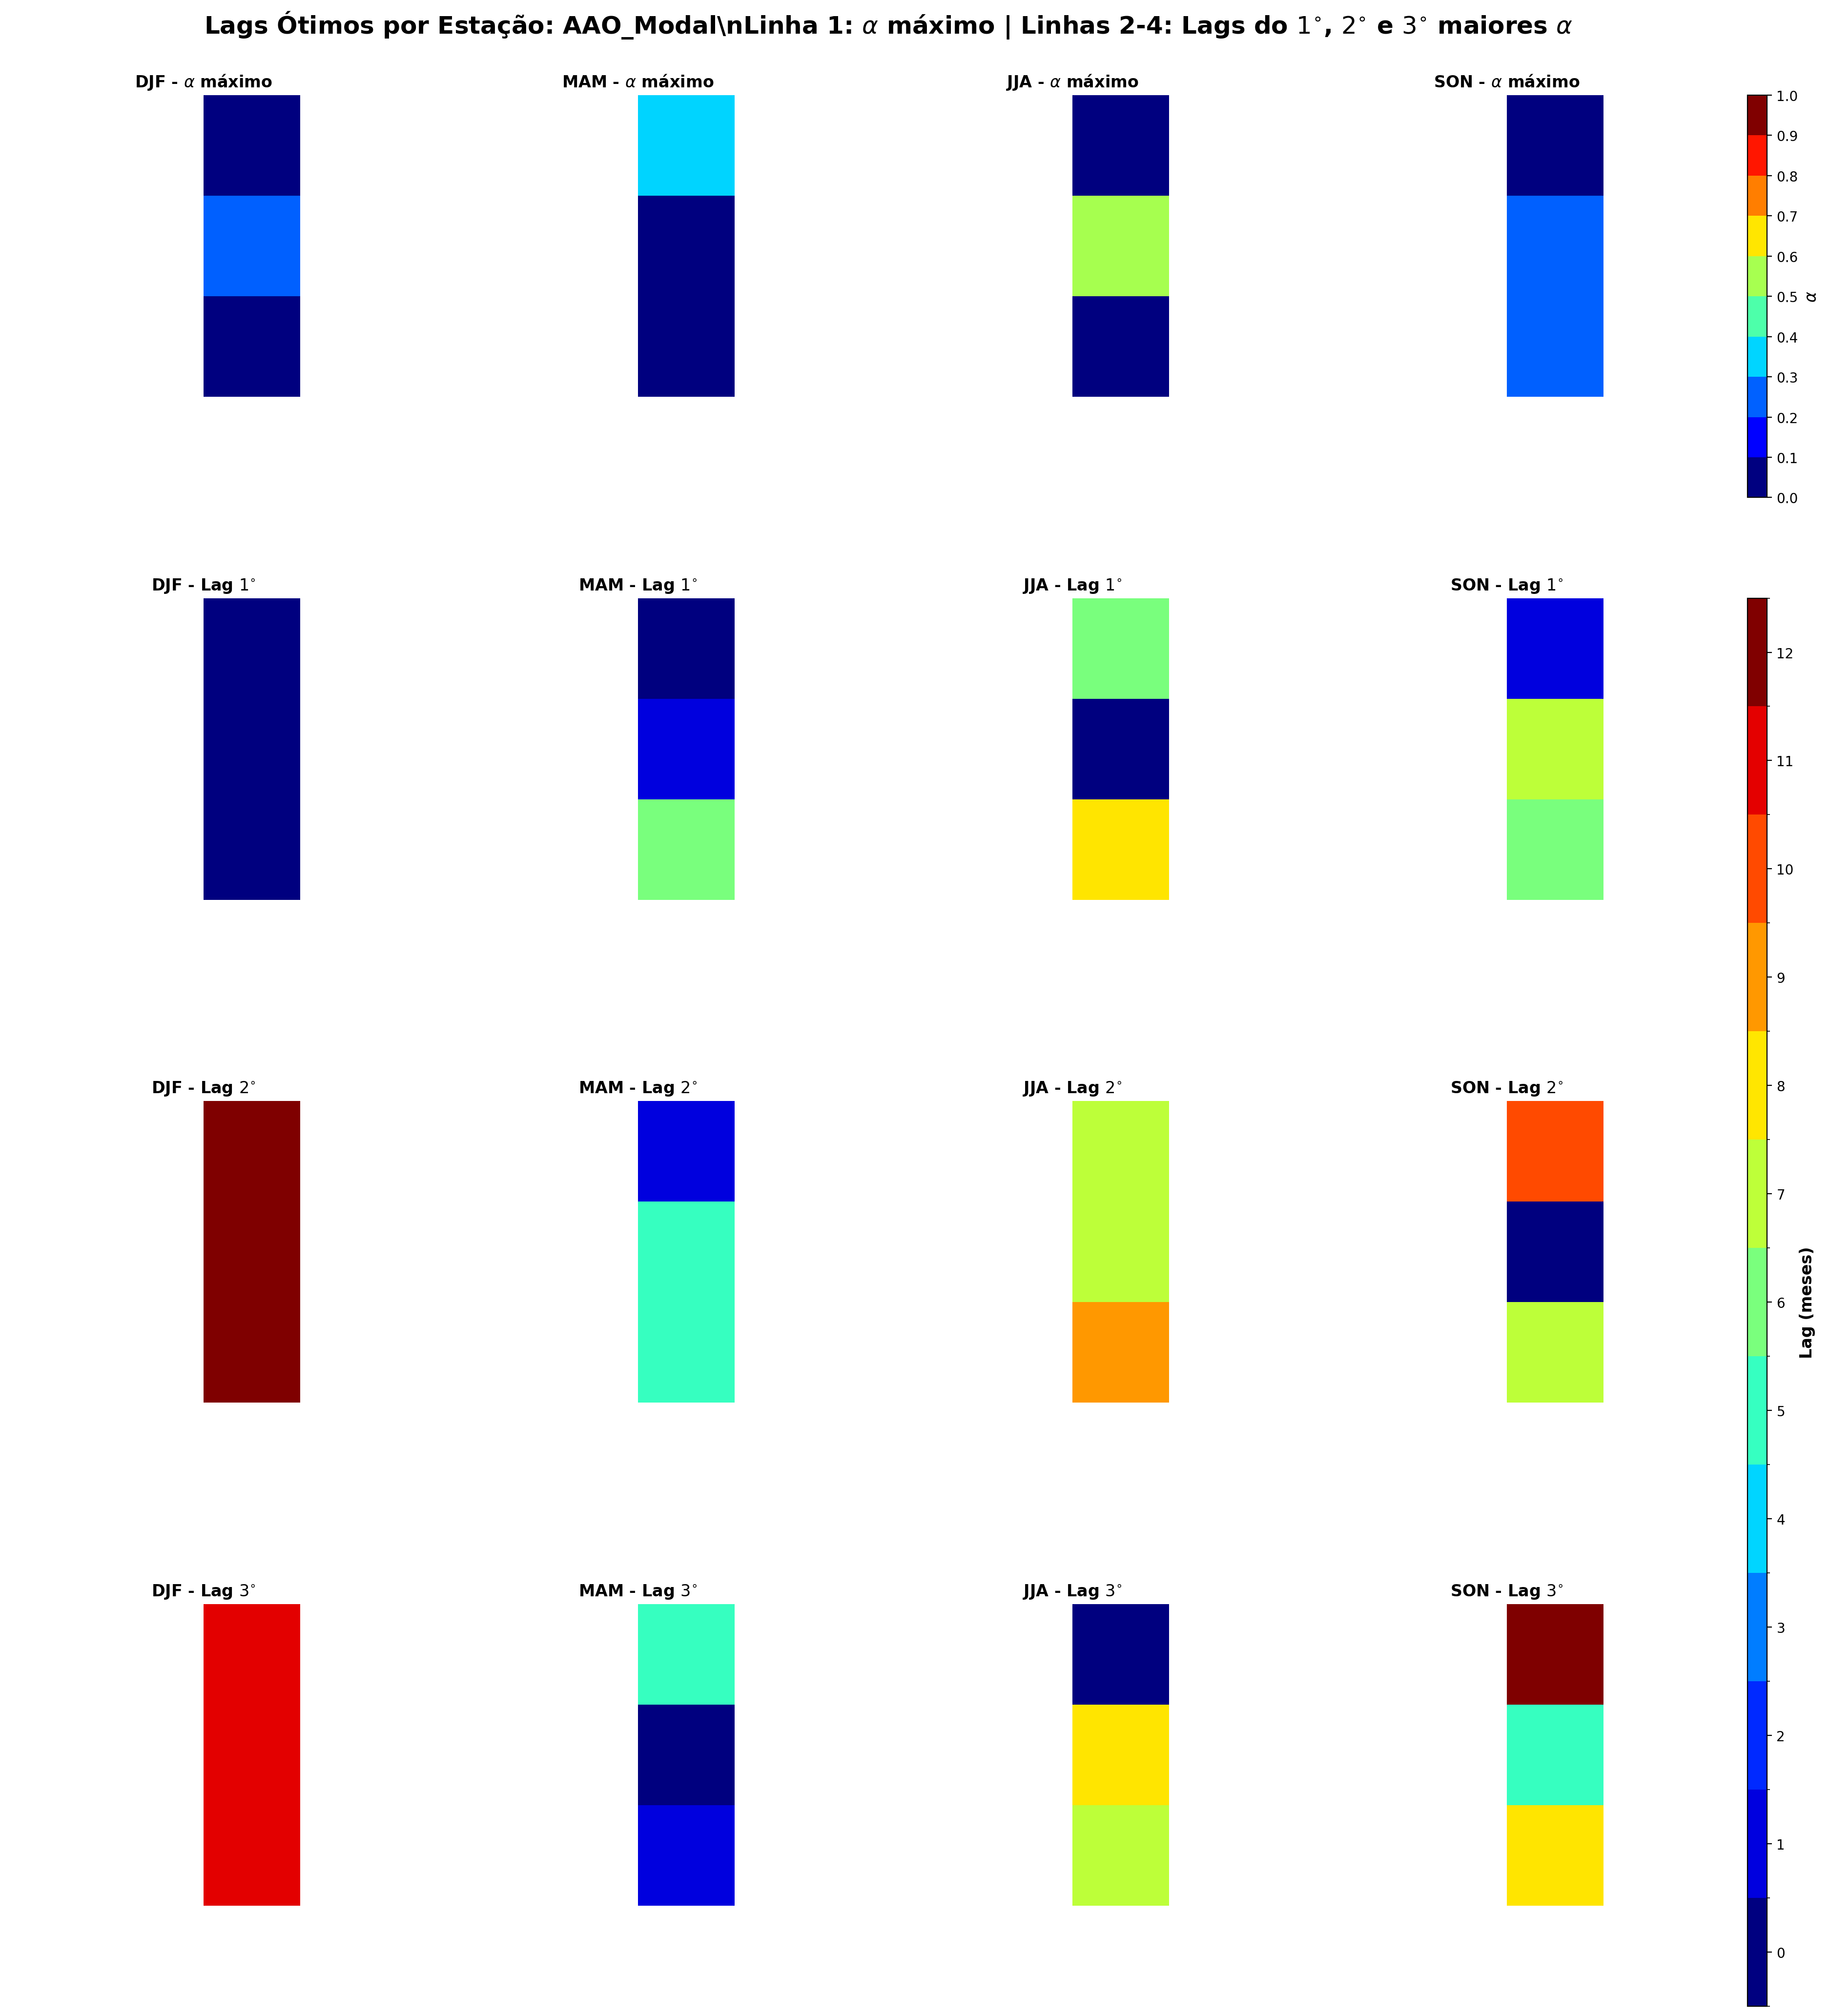

In [8]:
output_4x4 = output_dir / "4x4"
output_4x4.mkdir(exist_ok=True)

file_4x4 = plot_4x4_optimal_lags(ds_combined, 'AAO_Modal', output_4x4, seasons=seasons)

if file_4x4:
    print(f"✅ Plot 4×4: {file_4x4}")
    from IPython.display import Image, display
    display(Image(filename=file_4x4))

## 4. Plot 13×4 - Todos os Lags

✅ Plot 13×4: ../results/modal_xavier_rs/results/xavier_rs/plots/13x4/predep_13x4_grid_AAO_Modal.png


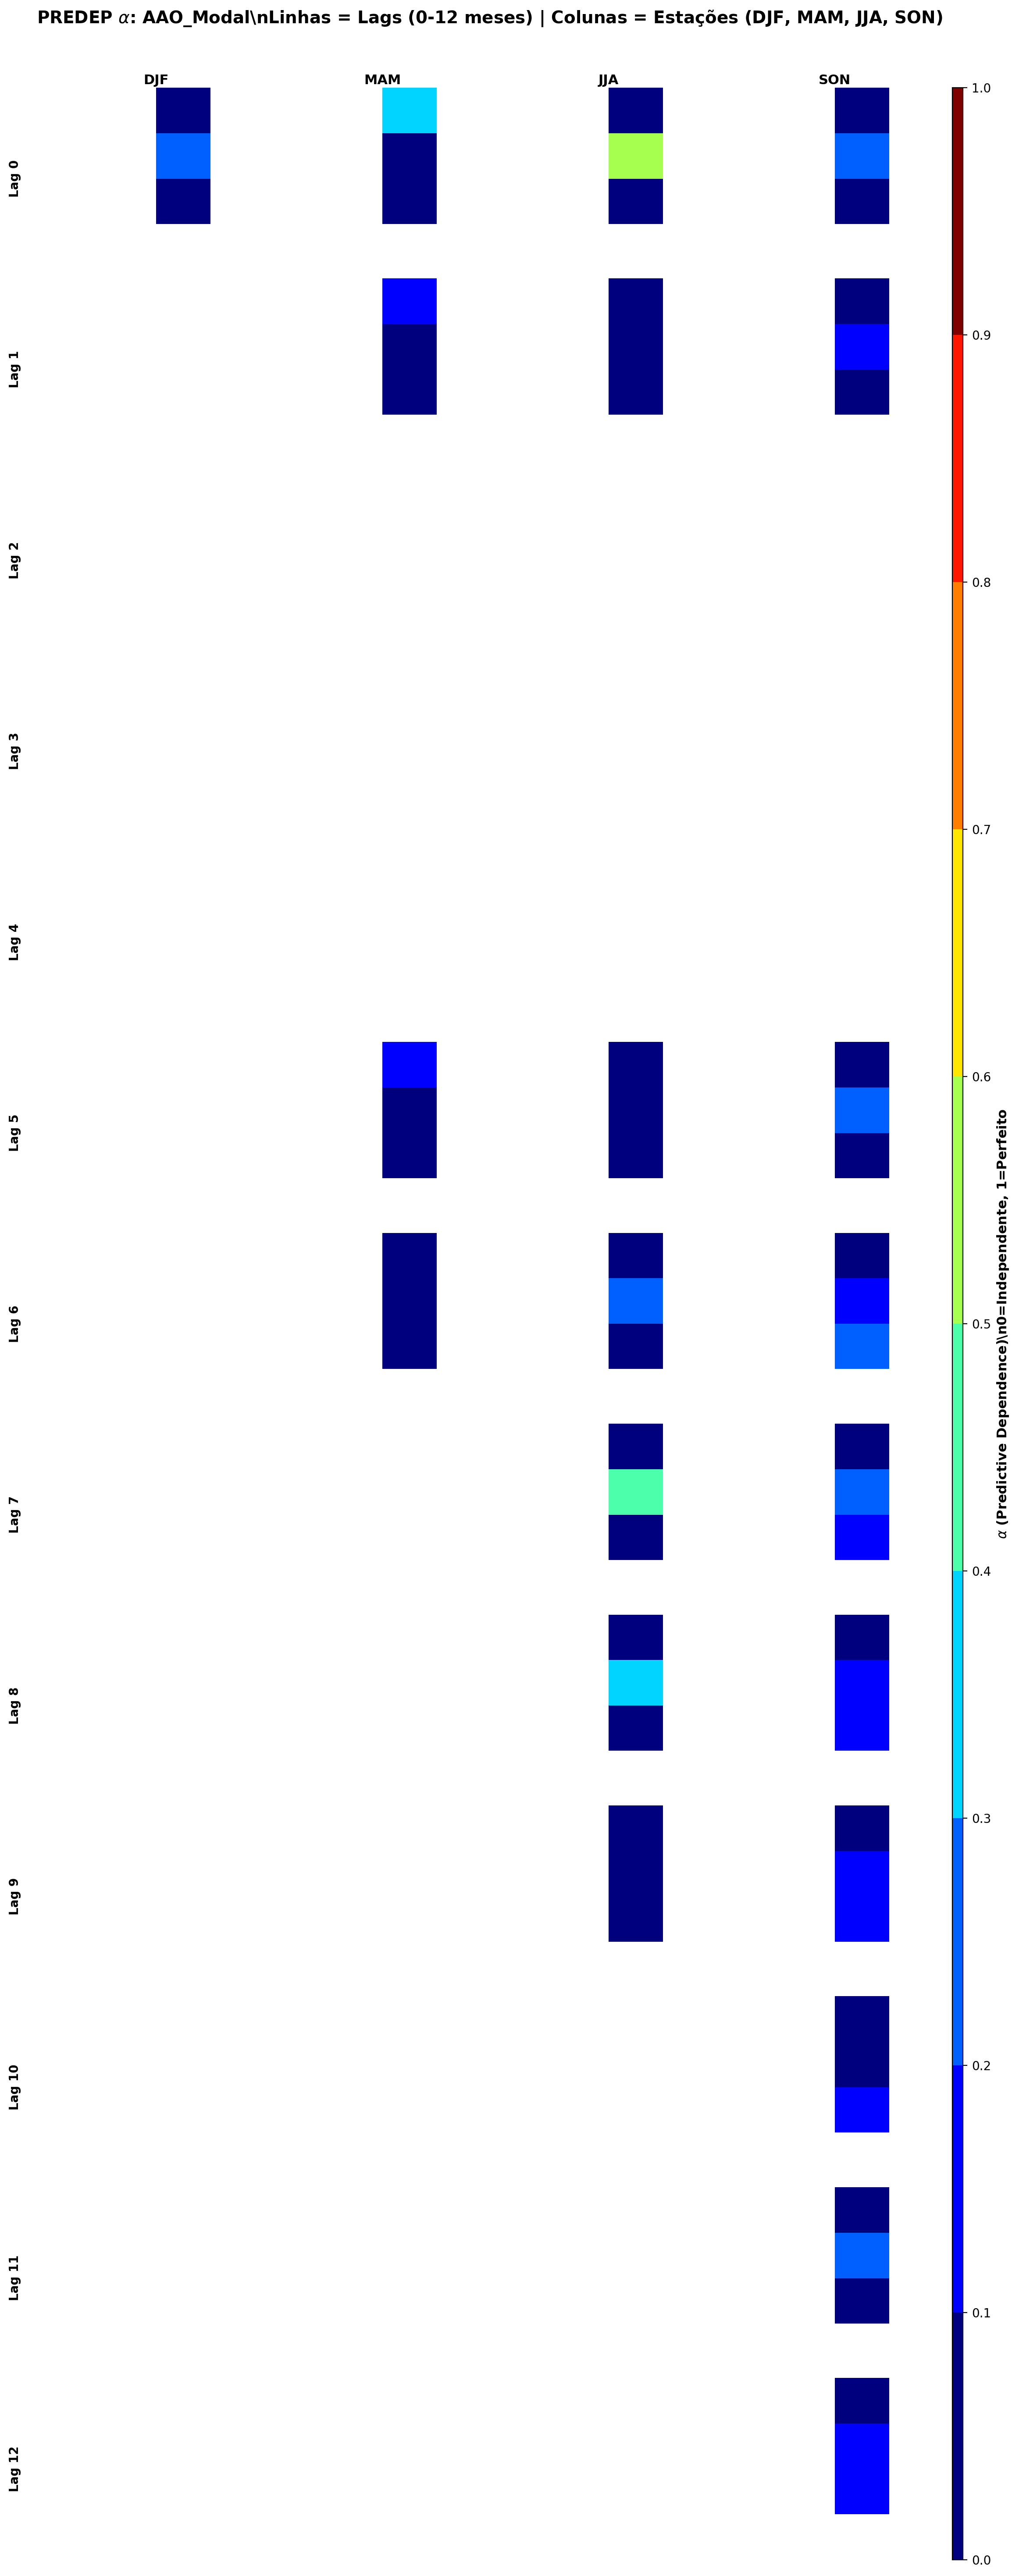

In [9]:
output_13x4 = output_dir / "13x4"
output_13x4.mkdir(exist_ok=True)

file_13x4 = plot_13x4_all_lags(ds_combined, 'AAO_Modal', output_13x4, seasons=seasons)

if file_13x4:
    print(f"✅ Plot 13×4: {file_13x4}")
    from IPython.display import Image, display
    display(Image(filename=file_13x4))

## 5. Mapas com Coordenadas Geográficas

In [10]:
# α máximo com extent
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, season in enumerate(seasons):
    alpha_data = ds_combined['predep_alpha'].isel(mov=0, season=idx)
    alpha_max = np.nanmax(alpha_data.values, axis=0)
    
    im = axes[idx].imshow(alpha_max, cmap='jet', vmin=0, vmax=1, aspect='auto', origin='lower',
                          extent=[lons.min(), lons.max(), lats.min(), lats.max()])
    axes[idx].set_xlabel('Longitude', fontsize=10)
    axes[idx].set_ylabel('Latitude', fontsize=10)
    axes[idx].set_title(f'{season} - α máximo', fontsize=12, fontweight='bold')
    axes[idx].grid(alpha=0.3)
    plt.colorbar(im, ax=axes[idx], fraction=0.046, label='α')

plt.suptitle('PREDEP Máximo - AAO × Precipitação RS', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(output_dir / 'mapa_alpha_coords.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Salvo: {output_dir / 'mapa_alpha_coords.png'}")

/tmp/ipykernel_529858/4041292499.py:7: RuntimeWarning: All-NaN slice encountered
  alpha_max = np.nanmax(alpha_data.values, axis=0)


✅ Salvo: ../results/modal_xavier_rs/results/xavier_rs/plots/mapa_alpha_coords.png


/tmp/ipykernel_529858/4041292499.py:20: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [11]:
# Lag ótimo com extent
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, season in enumerate(seasons):
    alpha_data = ds_combined['predep_alpha'].isel(mov=0, season=idx)
    all_lags = alpha_data.values
    
    # Calcular lag ótimo ignorando NaNs
    with np.errstate(invalid='ignore'):
        lag_optimal = np.full(all_lags.shape[1:], np.nan)
        for i in range(all_lags.shape[1]):
            for j in range(all_lags.shape[2]):
                col = all_lags[:, i, j]
                if not np.all(np.isnan(col)):
                    lag_optimal[i, j] = np.nanargmax(col)
    
    im = axes[idx].imshow(lag_optimal, cmap='jet', vmin=0, vmax=n_lags-1, aspect='auto', origin='lower',
                          extent=[lons.min(), lons.max(), lats.min(), lats.max()])
    axes[idx].set_xlabel('Longitude', fontsize=10)
    axes[idx].set_ylabel('Latitude', fontsize=10)
    axes[idx].set_title(f'{season} - Lag Ótimo', fontsize=12, fontweight='bold')
    axes[idx].grid(alpha=0.3)
    cbar = plt.colorbar(im, ax=axes[idx], fraction=0.046, ticks=range(n_lags))
    cbar.set_label('Lag (meses)', fontsize=10)

plt.suptitle('Lag Ótimo - AAO × Precipitação RS', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(output_dir / 'mapa_lag_coords.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Salvo: {output_dir / 'mapa_lag_coords.png'}")

ValueError: All-NaN slice encountered

## 6. Comparação Entre Estações

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

for season_idx, season in enumerate(seasons):
    alpha_data = ds_combined['predep_alpha'].isel(mov=0, season=season_idx)
    lag_means = [np.nanmean(alpha_data.isel(lag=lag).values) for lag in range(n_lags)]
    ax.plot(range(n_lags), lag_means, 'o-', linewidth=2, markersize=8, label=season)

ax.set_xlabel('Lag (meses)', fontsize=12)
ax.set_ylabel('α médio', fontsize=12)
ax.set_title('Comparação PREDEP Entre Estações', fontsize=14, fontweight='bold')
ax.set_xticks(range(n_lags))
ax.grid(alpha=0.3)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(output_dir / 'comparacao_estacoes.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Salvo: {output_dir / 'comparacao_estacoes.png'}")